## Integración numérica. Clase de física computacional

Queremos aproximar una integral $\int_{a}^{b} f(x) dx \sim I(a,b)$ con una función de estos dos parámetros.

Como queremos calcular áreas bajo curvas, y un método aproximado para calcularlo es usar sumas de Riemman.

$$I(a,b) = \lim_{n\rightarrow \infty}\sum_{i = 1}^{n} f(x_i)\Delta x_i$$

Otra forma sofisticada de aproximar esta área en vez de emplear rectángulos empleamos trapecios, donde a un intervalo $[a,b]$ lo dividimos en $N$ particiones y cada una con un grosor $h$, esto es:

$$(b-a)=Nh$$

y de este modo podemos aproximar a la integral como:

$$I(a,b) \sim \frac{h}{2}\left[f(a)+f(a+h)+ f(a+2h) +...+ f(a+kh) \right]$$

$$I(a,b) \sim \frac{h}{2} \sum_{k=0}^{N}f(a+kh)$$

$$\boxed{I(a,b) \sim h\left[\frac{f(a) + f(b)}{2}+ \sum_{k=1}^{N-1}f(a+kh)\right]}$$



Ejemplo: aproximar la integral de $f(x)= x²+3x+9$ en $(-2,3)$

In [8]:
def f(x):
    return x**2+3*x+9

In [14]:
a = -2
b = 3
N = int(input("Ingrese la cantidad de particiones que quieres hacer"))
h = (b-a)/N

Integral = 0
Int1 = (f(a)+f(b))/2

for i in range(1, N):
    Integral += f(a+i*h)

I = h*(Integral + Int1)
print(I)

Ingrese la cantidad de particiones que quieres hacer 10000


64.16666687499992


In [15]:
h

0.0005

In [20]:
def Trapecio(f,a,b,N):
    h = (b-a)/N

    Integral = 0
    Int1 = (f(a)+f(b))/2

    for i in range(1, N):
        Integral += f(a+i*h)

    I = h*(Integral + Int1)
    return I

In [21]:
Trapecio(f,-2,3,1000)

64.16668750000001

In [2]:
import numpy as np
def g(y):
    return (1-y)**5 + 3*np.sin(y)+2

In [26]:
float(Trapecio(g,-5,10,1000))

-80764.62545557054

In [14]:
import matplotlib as mpl
mpl.rc('text', usetex = True)

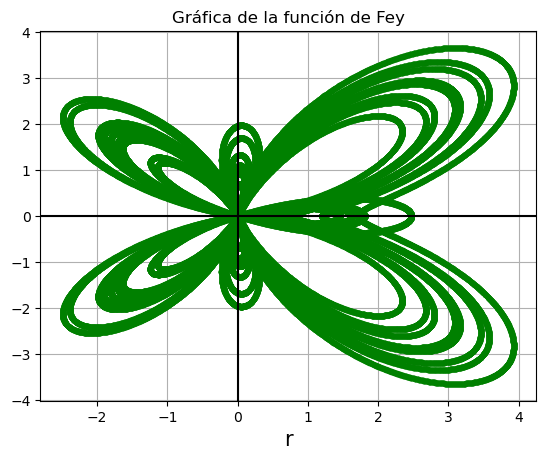

In [6]:
import numpy as np
import matplotlib.pyplot as plt
t = np.linspace(0,24*np.pi, 100000)
r = np.exp(np.cos(t)) - 2*np.cos(4*t) + (np.sin(t/12))**5
x = r*np.cos(t)
y = r*np.sin(t)

plt.plot(x,y,"g.")
plt.title("Gráfica de la función de Fey")
plt.xlabel("r", fontsize = 15)

plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')

plt.grid()

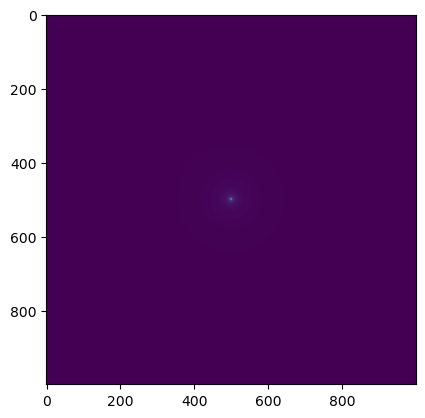

In [13]:
from pylab import scatter,xlabel,ylabel,xlim,ylim,show,imshow,gray

k=1
q=1
x = np.linspace(-0.5,0.5,1000)
y = np.linspace(-0.5,0.5,1000)

X,Y= np.meshgrid(x,y) #EL dominio son las matrices.

r = np.sqrt(X**2+Y**2)

phi = (k*q)/r

plt.imshow(phi)

Existen dos tipos de errores asociados en los cálculo.

1.- Error de método: propioo de cómo estamos definiendo nuestras aproximaciones.

2.- Error de redondeo: inherente a las capacidades de la propia máquina, entre mayor poder computacional menor el error de redondeo.

## Regla de Simpson

Es una aproximación que ya emplea polinomios de grado n para aproximar la integral de una función, si lo hacemos con parábolas vamos a necesitar 3 puntos para definirla, en comparación de dos necesarios del método del trapecio, además que la catidad de particiones tiene que ser par, de lo contrario no funciona.

Este método ocupa la mitad de iteraciones en comparación con el método del trapecio.

$$\boxed{I \sim \frac{h}{3} \left[(f(a) + f(b)) + 4 \sum_{k=1}^{\frac{N}{2}} f(a + [2k-1]h) + 2\sum_{k = 1}^{\frac{N}{2}-1}f(a+2kh))\right]}$$

Trapecio

In [3]:
import numpy as np
def g(y):
    return (1-y)**5 + 3*np.sin(y)+2

In [6]:
a = -2
b = 3
N = int(input("Ingrese la cantidad de particiones que quieres hacer"))
h = (b-a)/N

Integral = 0
Int1 = (g(a)+g(b))/2

for i in range(1, N):
    Integral += g(a+i*h)

I = h*(Integral + Int1)
print(I)

Ingrese la cantidad de particiones que quieres hacer 100


122.62221737417765


In [21]:
a = -2
b = 3
N = int(input("Ingrese la cantidad de particiones que quieres hacer:"))
h = (b-a)/N

suma1 = 0
suma2 = 0
extremos = f(a)+f(b)

for k in range(1,int(N/2)):
    suma1 += f(a+(2*k-1)*h)
for k in range(1, int(N/2-1)):
    suma2 += f(a+2*k*h)

Integral = 1/3*h*(extremos + 4*suma1 + 2*suma2)

print(Integral)

Ingrese la cantidad de particiones que quieres hacer: 1000


63.89726616666666


Como funciones:

In [16]:
def Trapecio(f,a,b,N):
    h = (b-a)/N

    Integral = 0
    Int1 = (f(a)+f(b))/2

    for i in range(1, N):
        Integral += f(a+i*h)

    I = h*(Integral + Int1)
    return I

In [64]:
def simpson2(f,a,b,n):
    if n%2 != 0 or n < 0:
        raise ValueError("Este método requiere de una cantidad positiva par de puntos en la refinación del intervalo.")
    h = (b-a)/n
    suma1 = 0
    suma2 = 0
    N = int(n/2)
    for k in range(1,N+1):
        suma1 += f(a+(2*k-1)*h)
    for j in range(1,N):
        suma2 += f(a+(2*j*h))
    IntegralAprox = (1/3)*h*((f(a) + f(b)) + 4*suma1 + 2*suma2)
    return IntegralAprox

In [65]:
import numpy as np
def g(y):
    return (1-y)**5 + 3*np.sin(y)+2

In [66]:
def f(x):
    return x**2+3*x+9

In [67]:
print(Trapecio(g,-5,10,10000))

-80764.1367354254


In [68]:
print(simpson2(g,-5,10,100))

-80764.13938310785


In [69]:
print(Trapecio(f,-2,3,10000))


64.16666687499992


In [70]:
print(simpson2(f,-2,3,1001))

ValueError: Este método requiere de una cantidad positiva par de puntos en la refinación del intervalo.

In [71]:
print(simpson2(f,-2,3,100))

64.16666666666667


## Fórmula de Newton-Cotes

Es la representación general de los métodos aproximados del trapecio, de simpson o de la regla de Boole.

Primero tengo que definir el grado del polinomio con el que quiero aproximar mi función dentro del inervalo, y con eso defino la cantidad de $x_k$ voy a necesitar por partición.

$$\int_{a}^{b} f(x)dx \approx  h \sum_{k=0}^{N}\alpha_k f(x_k)$$

donde $\alpha_k$ son los pesos y $x_k$ las raíces de los polinomios con los que queremos aproximar.
Los polinomios de Legendre tienen todas sus raíces en el intervalo de Legendre.

## Caudraturas de Gauss: Fórmula de Gauss - Legendre

Vamos a partir de la fórmula de Newton-Cotes: 

donde $w_k = h\alpha_k$
$$\int_{a}^{b} f(x)dx \approx  \sum_{k=0}^{N}w_k f(x_k)$$


Definimos con $m \neq k$:
$$P_k(x)= \prod_{m=1,2,...,N}\frac{x-x_m}{x_k-x_m}$$
$$P_k(x_m)=\delta_{km}$$

Si $$\int_{a}^{b} f(x)dx \approx  \int_{a}^{b} \phi(x)dx$$
donde $$\phi(x) = \sum_{k=1}^{N}f(x_k)P_k(x)$$
entonces cuando evaluamos en $x=x_m$
obtenemos que $$\phi(x_m) = \sum_{k=1}^{N}f(x_k)\delta_{km} = f(x_m)$$

Estos nos muestra que si exite un valor de $f$ para la $m$-ésima raíz del polonimio.

Siguiendo con el álgebra tenemos:

$$\int_{a}^{b} f(x)dx \approx  \int_{a}^{b} \phi(x)dx = \int_{a}^{b}\sum_{k=1}^{N}f(x_k)P_k(x)dx$$
$$\Rightarrow \int_{a}^{b} f(x)dx \approx \sum_{k=1}^{N}f(x_k)\int_{a}^{b}P_k(x)dx = \sum_{k=0}^{N}w_k f(x_k)$$
donde $$ w_k = \int_{a}^{b}P_k(x)dx$$

pero sabemos que los polinomios de Legendre solo están definidos en $[-1,1]$

entonces tenemos que adecuar los límites de integración a $[a,b]$

si definimos el siguiente cambio de variable tenemos:

$$x_k^{'} = \frac{b-a}{2}x_k + \frac{b-a}{2}$$

entonces

$$w_k^{'} = \int_{a}^{b}P_k(x)dx$$

## Diferenciación numérica

In [13]:
def DiferenciaciónCentral(f,x,h):
    return (f(x+(h/2))-f(x-(h/2)))/h

In [40]:
import numpy as np

def fprueba(x):
    return x**2

def fprueba2(x):
    return (4*(np.cos(x))**2 - 1)


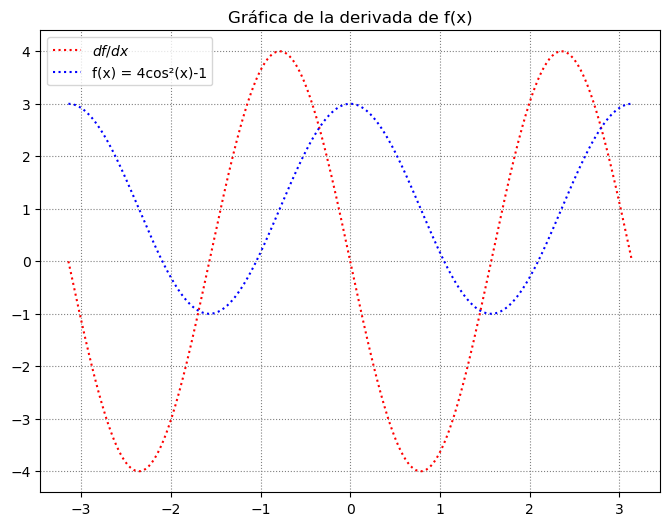

In [80]:
import matplotlib.pyplot as plt

ejex = np.linspace(-np.pi,np.pi,1000)
ejey = [[],[]]
for i in range(0,len(ejex)):
    yi = DiferenciaciónCentral(fprueba2,ejex[i],0.001)
    yk = fprueba2(ejex[i])
    ejey[0].append(yi)
    ejey[1].append(yk)


plt.figure(figsize=(8,6))

plt.title("Gráfica de la derivada de f(x)")
plt.plot(ejex,ejey[0], "r:", label = "$df/dx$")
plt.plot(ejex,ejey[1], "b:", label = "f(x) = 4cos²(x)-1") 
plt.legend()
plt.grid(linestyle =":",color="gray")